In [1]:
import pandas as pd
df=pd.read_csv('innings_deliveries.csv')
df

,team,over,batter,bowler,non_striker,runs_batter,runs_extras,runs_total,player_out,wicket_kind,fielders
0,Royal Challengers Bengaluru,0,V Kohli,I Sharma,F du Plessis,0,0,0,NaN,NaN,[]
1,Royal Challengers Bengaluru,0,V Kohli,I Sharma,F du Plessis,1,0,1,NaN,NaN,[]
2,Royal Challengers Bengaluru,0,F du Plessis,I Sharma,V Kohli,1,0,1,NaN,NaN,[]
3,Royal Challengers Bengaluru,0,V Kohli,I Sharma,F du Plessis,0,0,0,NaN,NaN,[]
4,Royal Challengers Bengaluru,0,V Kohli,I Sharma,F du Plessis,2,0,2,NaN,NaN,[]
...,...,...,...,...,...,...,...,...,...,...,...
242,Delhi Capitals,18,Kuldeep Yadav,Mohammed Siraj,I Sharma,1,0,1,NaN,NaN,[]
243,Delhi Capitals,18,I Sharma,Mohammed Siraj,Kuldeep Yadav,0,1,1,NaN,NaN,[]
244,Delhi Capitals,18,I Sharma,Mohammed Siraj,Kuldeep Yadav,0,0,0,NaN,NaN,[]
245,Delhi Capitals,18,I Sharma,Mohammed Siraj,Kuldeep Yadav,0,0,0,NaN,NaN,[]


# 1.Clean the dataset

In [2]:
df.isnull().sum()

team             0
over             0
batter           0
bowler           0
non_striker      0
runs_batter      0
runs_extras      0
runs_total       0
player_out     228
wicket_kind    228
fielders         0
dtype: int64

In [3]:
df['player_out']=df['player_out'].fillna('Not Out')
df['wicket_kind']=df['wicket_kind'].fillna('No wicket')
df.isnull().sum()

team           0
over           0
batter         0
bowler         0
non_striker    0
runs_batter    0
runs_extras    0
runs_total     0
player_out     0
wicket_kind    0
fielders       0
dtype: int64

In [4]:
#removing Space
df['team']=df['team'].str.strip()
df['batter']=df['batter'].str.strip()
df['bowler']=df['bowler'].str.strip()
df['non_striker']=df['non_striker'].str.strip()

# 2.plot the visualizing the run distribution per over for both teams to illustrate the scoring trends throughout the innings(use lineplot from seaborn)


In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
over_runs=df.groupby(['team','over'])['runs_total'].sum().reset_index()
over_runs.head(5)

,team,over,runs_total
0,Delhi Capitals,0,9
1,Delhi Capitals,1,15
2,Delhi Capitals,2,4
3,Delhi Capitals,3,2
4,Delhi Capitals,4,13


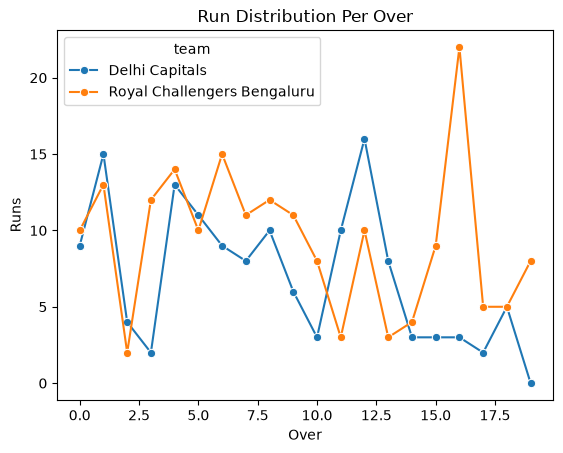

In [7]:
sns.lineplot(data=over_runs,x='over',y='runs_total',hue='team',marker='o')
plt.title('Run Distribution Per Over')
plt.xlabel('Over')
plt.ylabel('Runs')
plt.show()

# 3.create a bar chart to visualize the top contributors in terms of runs


In [8]:
runs=df.groupby('batter')['runs_batter'].sum()
top_runs=runs.sort_values(ascending=False).head(10)
top_runs

batter
AR Patel           57
RM Patidar         52
WG Jacks           41
C Green            32
SD Hope            29
V Kohli            27
J Fraser-McGurk    21
MK Lomror          13
Rasikh Salam       10
Kuldeep Yadav       6
Name: runs_batter, dtype: int64

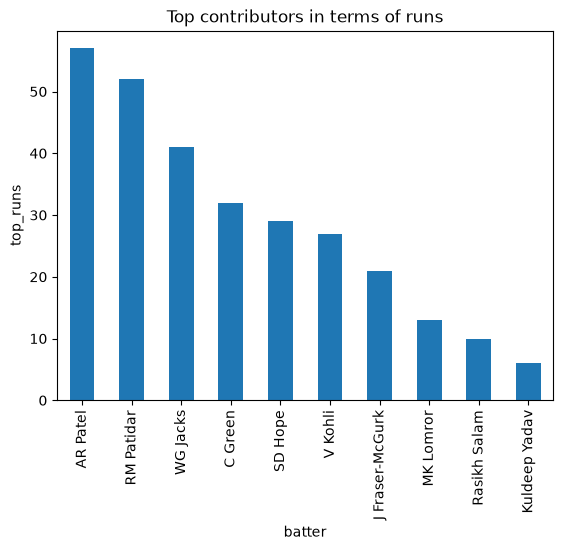

In [9]:
top_runs.plot(kind='bar')
plt.title('Top contributors in terms of runs')
plt.xlabel('batter')
plt.ylabel('top_runs')
plt.show()

# 4.combined bar and line plot provides a comprehensive overview of the bowling performance of each team.(Wickets and Economy Rate)

In [10]:
bowling=df.groupby(['team','bowler']).agg(Runs=('runs_total','sum'),Balls=('runs_total','count')).reset_index()

#Economy rate
bowling['Economy Rate']=bowling['Runs']/bowling['Balls']*6

#Wickets
df['is_wicket']=df['player_out']!='Not Out'
wickets=df[df['is_wicket']].groupby(['team','bowler']).size().reset_index(name='wickets')

In [11]:
bowling=bowling.merge(wickets,on=['team','bowler'],how='left')
bowling

,team,bowler,Runs,Balls,Economy Rate,wickets
0,Delhi Capitals,C Green,19,26,4.384615,2.0
1,Delhi Capitals,KV Sharma,19,12,9.500000,NaN
2,Delhi Capitals,LH Ferguson,24,24,6.000000,2.0
3,Delhi Capitals,Mohammed Siraj,33,26,7.615385,1.0
4,Delhi Capitals,Swapnil Singh,9,6,9.000000,1.0
5,Delhi Capitals,WG Jacks,16,6,16.000000,NaN
6,Delhi Capitals,Yash Dayal,20,20,6.000000,4.0
7,Royal Challengers Bengaluru,AR Patel,24,18,8.000000,NaN
8,Royal Challengers Bengaluru,I Sharma,31,21,8.857143,1.0
9,Royal Challengers Bengaluru,KK Ahmed,32,24,8.000000,2.0


In [12]:
bowling['wickets']=bowling['wickets'].fillna(0)
bowling

,team,bowler,Runs,Balls,Economy Rate,wickets
0,Delhi Capitals,C Green,19,26,4.384615,2.0
1,Delhi Capitals,KV Sharma,19,12,9.500000,0.0
2,Delhi Capitals,LH Ferguson,24,24,6.000000,2.0
3,Delhi Capitals,Mohammed Siraj,33,26,7.615385,1.0
4,Delhi Capitals,Swapnil Singh,9,6,9.000000,1.0
5,Delhi Capitals,WG Jacks,16,6,16.000000,0.0
6,Delhi Capitals,Yash Dayal,20,20,6.000000,4.0
7,Royal Challengers Bengaluru,AR Patel,24,18,8.000000,0.0
8,Royal Challengers Bengaluru,I Sharma,31,21,8.857143,1.0
9,Royal Challengers Bengaluru,KK Ahmed,32,24,8.000000,2.0


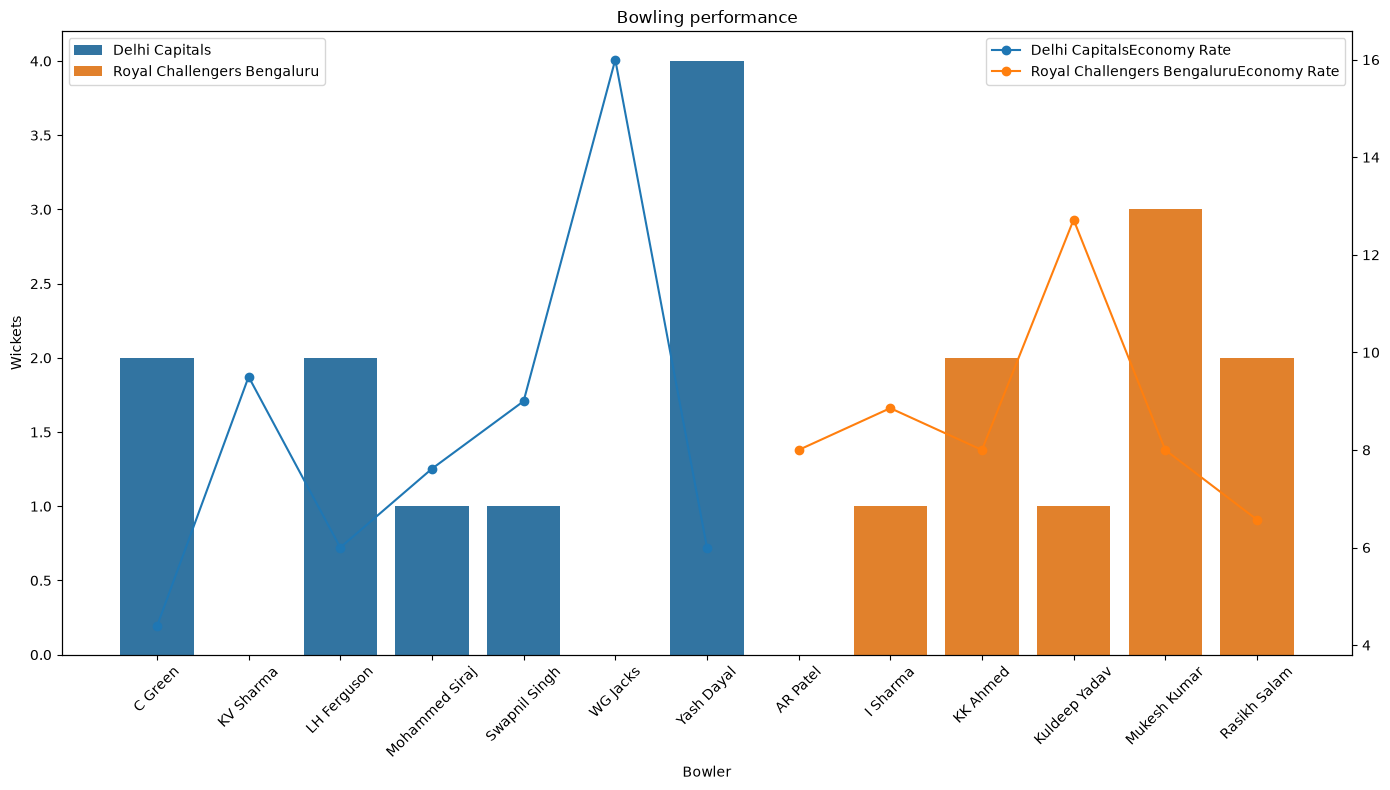

In [13]:
plt.figure(figsize=(14, 8))
ax1=sns.barplot(data=bowling,x='bowler',y='wickets',hue='team')
plt.title('Bowling performance')
plt.xlabel('Bowler')
plt.ylabel('Wickets')
ax1.legend(loc='upper left')
ax2 = plt.twinx()
for team in bowling['team'].unique():
    temp=bowling[bowling['team']==team]
    ax2.plot(temp['bowler'],temp['Economy Rate'],marker='o',label=team +'Economy Rate')
ax2.set_ylabel=('Economy_Rate')
ax1.tick_params(axis='x',labelrotation=45)
ax2.legend(loc='upper right')
plt.tight_layout()
plt.show()

# 5.pie chart - types of dismissals that occurred during the match to understand how most wickets were taken (e.g., caught, bowled, run out).

In [14]:
dismissals=df[df['wicket_kind']!='No wicket']['wicket_kind'].value_counts()
dismissals

wicket_kind
caught     13
run out     4
lbw         1
bowled      1
Name: count, dtype: int64

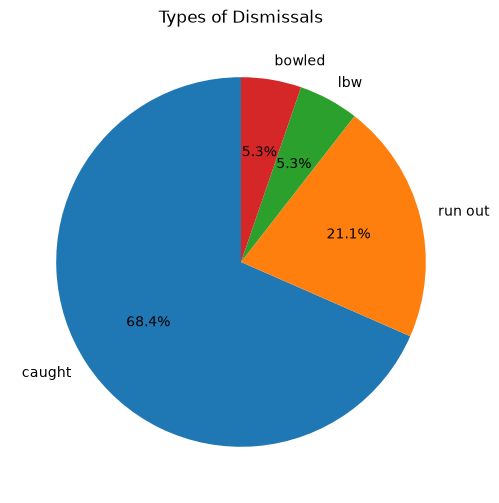

In [15]:
plt.figure(figsize=(6,6))
plt.pie(dismissals,labels=dismissals.index,autopct='%1.1f%%',startangle=90)
plt.title('Types of Dismissals')
plt.show()

# 6.Perform Partnerships Analysis by calculating and visualizing the most productive batting partnerships in the match

In [16]:
df['is_wicket']=df['player_out']!='Not Out'

df['partnership_id']=(df.groupby('team')['is_wicket'].cumsum()-df['is_wicket'].astype(int))
df['player1']=df[['batter','non_striker']].min(axis=1)
df['player2']=df[['batter','non_striker']].max(axis=1)


partnerships = df.groupby(['team','partnership_id','player1','player2'])['runs_total'].sum().reset_index()
partnerships = partnerships.sort_values('runs_total',ascending=False)
top_10 = partnerships.head(10)
top_10

,team,partnership_id,player1,player2,runs_total
12,Royal Challengers Bengaluru,2,RM Patidar,WG Jacks,88
4,Delhi Capitals,4,AR Patel,SD Hope,56
14,Royal Challengers Bengaluru,4,C Green,MK Lomror,37
6,Delhi Capitals,6,AR Patel,Rasikh Salam,37
10,Royal Challengers Bengaluru,0,F du Plessis,V Kohli,23
1,Delhi Capitals,1,Abishek Porel,J Fraser-McGurk,16
11,Royal Challengers Bengaluru,1,V Kohli,WG Jacks,13
13,Royal Challengers Bengaluru,3,C Green,WG Jacks,13
17,Royal Challengers Bengaluru,7,C Green,KV Sharma,9
0,Delhi Capitals,0,DA Warner,J Fraser-McGurk,8


In [17]:
top_10['Partnership']=(top_10['player1']+'&'+top_10['player2'])
top_10['Partnership']

12              RM Patidar&WG Jacks
4                  AR Patel&SD Hope
14                C Green&MK Lomror
6             AR Patel&Rasikh Salam
10             F du Plessis&V Kohli
1     Abishek Porel&J Fraser-McGurk
11                 V Kohli&WG Jacks
13                 C Green&WG Jacks
17                C Green&KV Sharma
0         DA Warner&J Fraser-McGurk
Name: Partnership, dtype: str

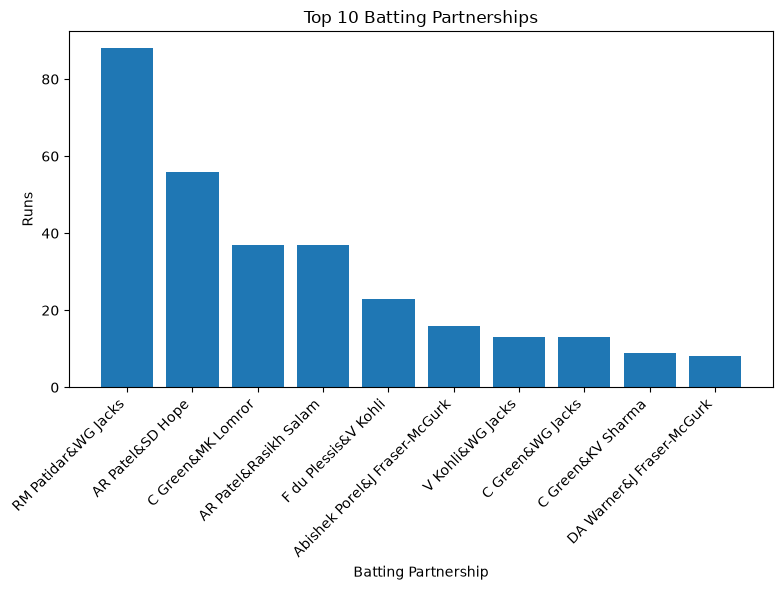

In [18]:
plt.figure(figsize=(8, 6))
plt.bar(top_10['Partnership'],top_10['runs_total'])
plt.title('Top 10 Batting Partnerships')
plt.xlabel('Batting Partnership')
plt.ylabel('Runs')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 7.Phase Analysis

In [19]:
def get_phase(over):
    if over<=5:
        return 'Powerplay'
    elif over<=14:
        return 'Middle'
    else:
        return 'Death'
df['phase']=df['over'].apply(get_phase)


In [20]:
phase_analysis=df.groupby(['team','phase']).agg(Runs=('runs_total','sum'),Balls=('runs_total','count')).reset_index()

In [21]:
phase_analysis['Runs Rate']=(phase_analysis['Runs']/phase_analysis['Balls'])*6

In [22]:
wickets=df[df['player_out'].notna()].groupby(['team','phase']).size().reset_index(name='wickets')

In [23]:
phase_analysis=phase_analysis.merge(wickets,on=['team','phase'],how='left')
phase_analysis['wickets']=phase_analysis['wickets'].fillna(0)
phase_analysis

,team,phase,Runs,Balls,Runs Rate,wickets
0,Delhi Capitals,Death,13,29,2.689655,29
1,Delhi Capitals,Middle,73,55,7.963636,55
2,Delhi Capitals,Powerplay,54,36,9.000000,36
3,Royal Challengers Bengaluru,Death,49,33,8.909091,33
4,Royal Challengers Bengaluru,Middle,77,57,8.105263,57
5,Royal Challengers Bengaluru,Powerplay,61,37,9.891892,37


In [24]:
phase_analysis['phase']=pd.Categorical(phase_analysis['phase'],categories=['Powerplay','Middle','Death'],ordered=True)
phase_analysis=phase_analysis.sort_values(['team','phase'])
phase_analysis

,team,phase,Runs,Balls,Runs Rate,wickets
2,Delhi Capitals,Powerplay,54,36,9.000000,36
1,Delhi Capitals,Middle,73,55,7.963636,55
0,Delhi Capitals,Death,13,29,2.689655,29
5,Royal Challengers Bengaluru,Powerplay,61,37,9.891892,37
4,Royal Challengers Bengaluru,Middle,77,57,8.105263,57
3,Royal Challengers Bengaluru,Death,49,33,8.909091,33


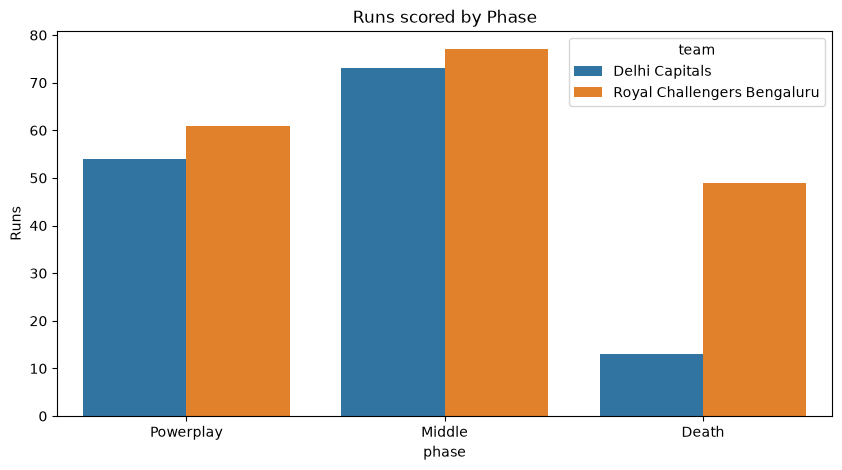

In [25]:
plt.figure(figsize=(10,5))
sns.barplot(data=phase_analysis,x='phase',y='Runs',hue='team')
plt.title('Runs scored by Phase')
plt.xlabel('phase')
plt.ylabel('Runs')
plt.show()

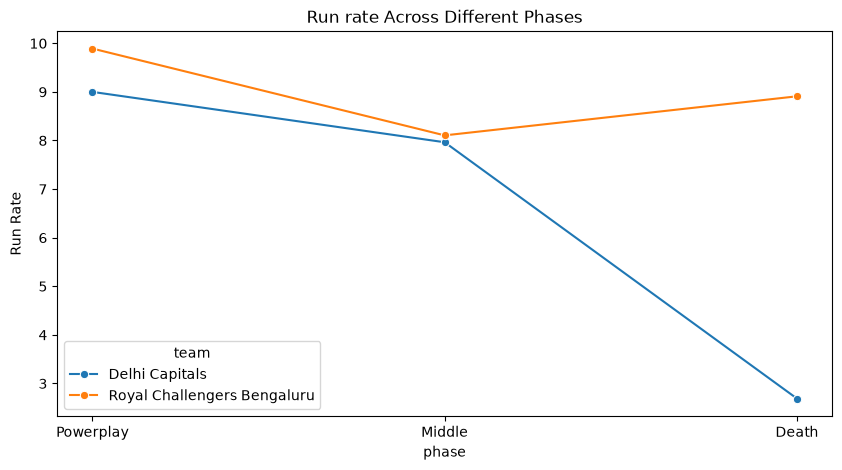

In [26]:
plt.figure(figsize=(10,5))
sns.lineplot(data=phase_analysis,x='phase',y='Runs Rate',hue='team',marker='o')
plt.title('Run rate Across Different Phases')
plt.xlabel('phase')
plt.ylabel('Run Rate')
plt.show()

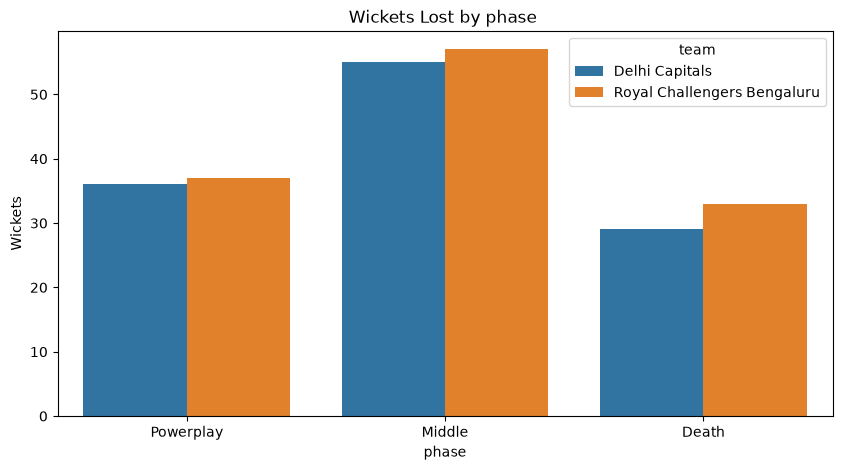

In [27]:
plt.figure(figsize=(10,5))
sns.barplot(data=phase_analysis,x='phase',y='wickets',hue='team')
plt.title('Wickets Lost by phase ')
plt.xlabel('phase')
plt.ylabel('Wickets')
plt.show()

# 8.calculate the strike rate for each batter and print the top 10 batters.


In [28]:
batter_stats=df.groupby('batter').agg(Runs=('runs_batter','sum'),Balls=('runs_batter','count')).reset_index()
batter_stats

,batter,Runs,Balls
0,AR Patel,57,40
1,Abishek Porel,2,3
2,C Green,32,24
3,DA Warner,1,2
4,F du Plessis,6,7
5,I Sharma,0,5
6,J Fraser-McGurk,21,8
7,KD Karthik,0,2
8,KV Sharma,6,4
9,Kuldeep Yadav,6,11


In [29]:
batter_stats['Strike Rate']=(batter_stats['Runs']/batter_stats['Balls'])*100
batter_stats

,batter,Runs,Balls,Strike Rate
0,AR Patel,57,40,142.500000
1,Abishek Porel,2,3,66.666667
2,C Green,32,24,133.333333
3,DA Warner,1,2,50.000000
4,F du Plessis,6,7,85.714286
5,I Sharma,0,5,0.000000
6,J Fraser-McGurk,21,8,262.500000
7,KD Karthik,0,2,0.000000
8,KV Sharma,6,4,150.000000
9,Kuldeep Yadav,6,11,54.545455


In [30]:
batter_stats=batter_stats.sort_values('Strike Rate',ascending=False)
top_10=batter_stats.head(10)
top_10

,batter,Runs,Balls,Strike Rate
6,J Fraser-McGurk,21,8,262.500000
18,V Kohli,27,14,192.857143
13,RM Patidar,52,34,152.941176
8,KV Sharma,6,4,150.000000
0,AR Patel,57,40,142.500000
19,WG Jacks,41,30,136.666667
2,C Green,32,24,133.333333
11,MK Lomror,13,10,130.000000
15,SD Hope,29,24,120.833333
4,F du Plessis,6,7,85.714286


# 9.Plot a graph to show the strike rate across different phases for top performers

In [31]:
top_players=top_10['batter'].tolist()
top_players

['J Fraser-McGurk',
 'V Kohli',
 'RM Patidar',
 'KV Sharma',
 'AR Patel',
 'WG Jacks',
 'C Green',
 'MK Lomror',
 'SD Hope',
 'F du Plessis']

In [32]:
top_batters=df[df['batter'].isin(top_players)]

In [33]:
phase_sr=top_batters.groupby(['batter','phase']).agg(Runs=('runs_batter','sum'),Balls=('runs_batter','count')).reset_index()

In [34]:
phase_sr['Strike Rate']=(phase_sr['Runs']/phase_sr['Balls'])*100
phase_sr    

,batter,phase,Runs,Balls,Strike Rate
0,AR Patel,Death,0,5,0.000000
1,AR Patel,Middle,47,27,174.074074
2,AR Patel,Powerplay,10,8,125.000000
3,C Green,Death,26,16,162.500000
4,C Green,Middle,6,8,75.000000
5,F du Plessis,Powerplay,6,7,85.714286
6,J Fraser-McGurk,Powerplay,21,8,262.500000
7,KV Sharma,Death,6,4,150.000000
8,MK Lomror,Death,12,9,133.333333
9,MK Lomror,Middle,1,1,100.000000


In [35]:
phase_sr['phase']=pd.Categorical(phase_sr['phase'],categories=['Powerplay','Middle','Death'],ordered=True)

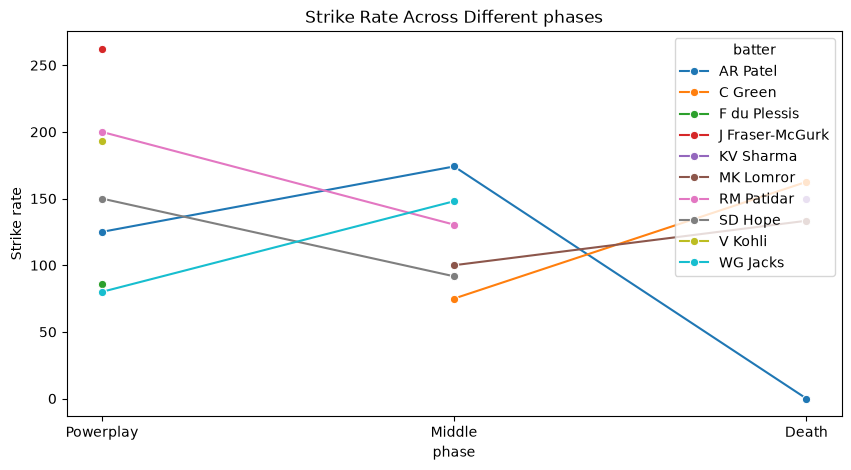

In [36]:
plt.figure(figsize=(10,5))
sns.lineplot(data=phase_sr,x='phase',y='Strike Rate',hue='batter',marker='o')
plt.title('Strike Rate Across Different phases')
plt.xlabel('phase')
plt.ylabel('Strike rate')
plt.show()

# 10.Plot a graph to show the Cumulative Runs with Wickets for RCB and DC

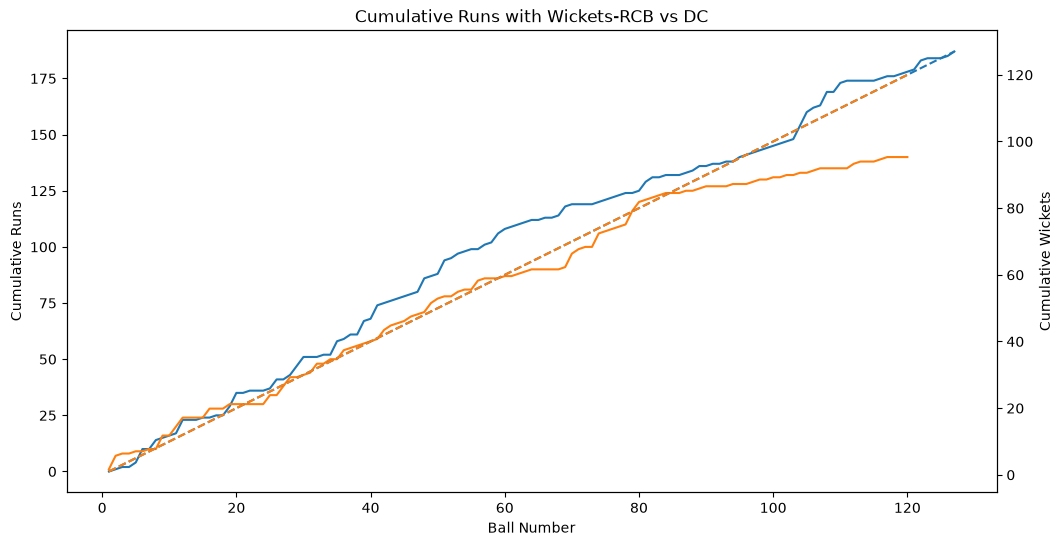

In [37]:
df['Cumulative Runs']=df.groupby('team')['runs_total'].cumsum()
df['Wicket']=df['player_out'].notna().astype(int)
df['Cumulative Wickets']=df.groupby('team')['Wicket'].cumsum()
fig,ax1=plt.subplots(figsize=(12,6))

for team in df['team'].unique():
    team_data=df[df['team']==team]
    ball_number=range(1,len(team_data)+1)

    ax1.plot(ball_number,team_data['Cumulative Runs'],label=team)
ax1.set_xlabel('Ball Number')
ax1.set_ylabel('Cumulative Runs')

ax2 = ax1.twinx()
for team in df['team'].unique():
    team_data = df[df['team']==team]
    ball_number = range(1, len(team_data) + 1)

    ax2.plot(ball_number,team_data['Cumulative Wickets'],linestyle='--',label=team+'Wickets')
ax2.set_ylabel('Cumulative Wickets')
plt.title('Cumulative Runs with Wickets-RCB vs DC')
plt.show()